This sample code uses the cv2 package for image interpretation. Specifically, we want to extract individual cells from a grid in an image. 


As written, this is incomplete. Here are a few issues:

1) cells that are the wrong shape to be grades should be discarded
2) cells that are the right shape need to be trimmed to all be exactly the same shape; there is a bit of variation in size
3) cells that are too blank should be discarded; the darkness variable can help discern this


After you've got that done:





In [1]:
%pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


In [2]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt
import PIL.Image as Image
# import functions from file
from gradesheet_fxns import *


['grbfewyhc.tif', 'hloxxnfer.tif', 'yeprnfkcm.tif']


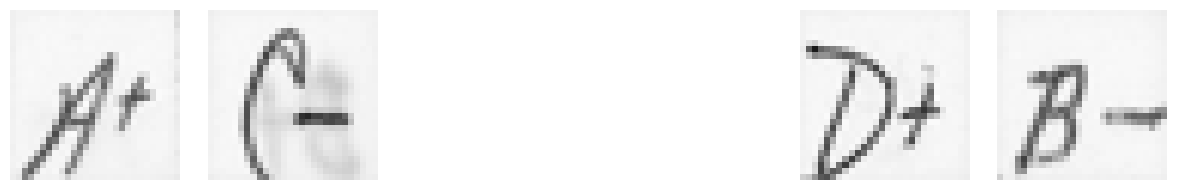

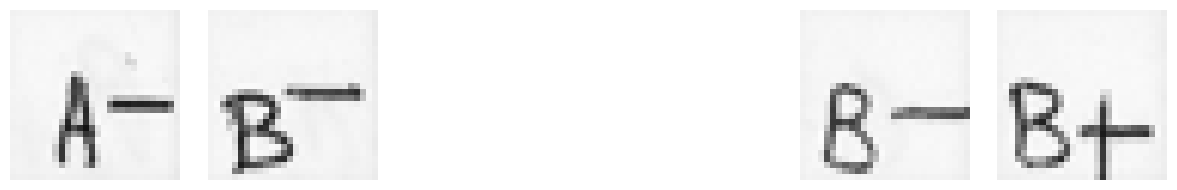

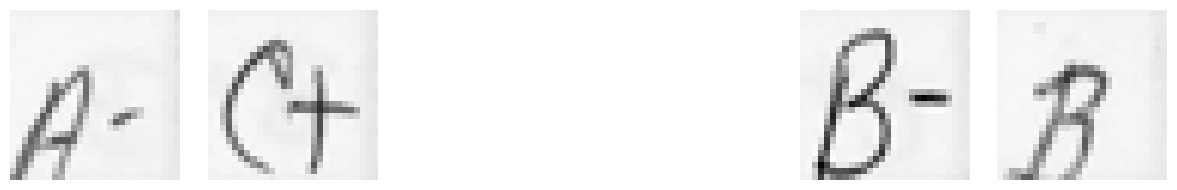

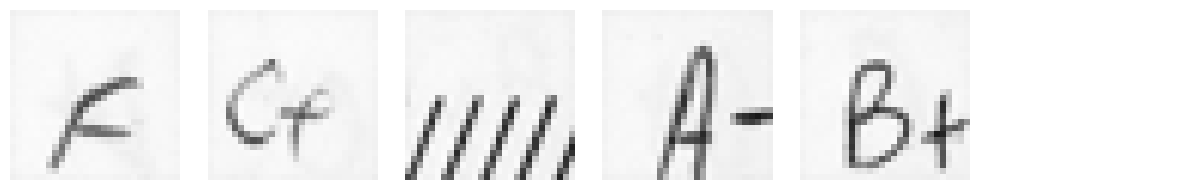

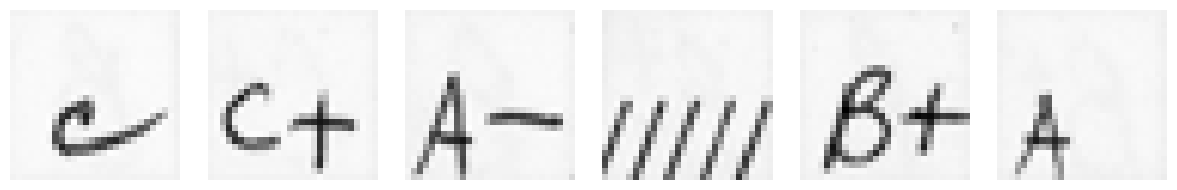

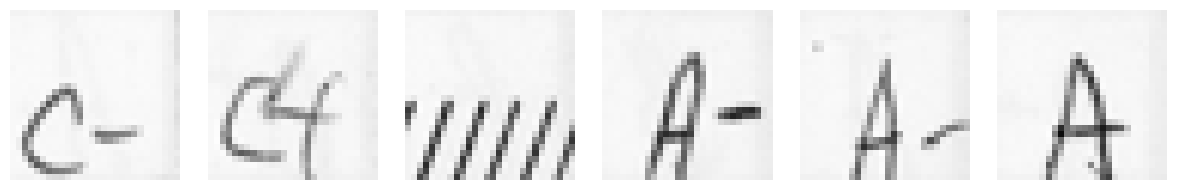

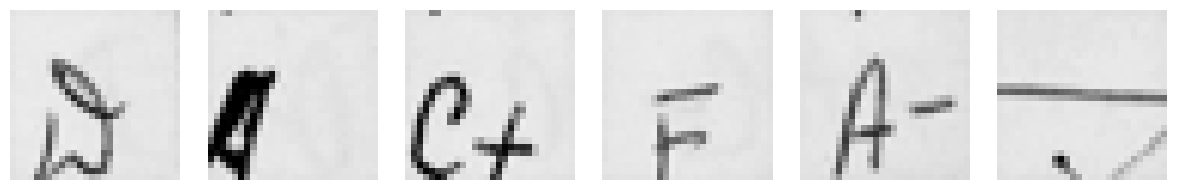

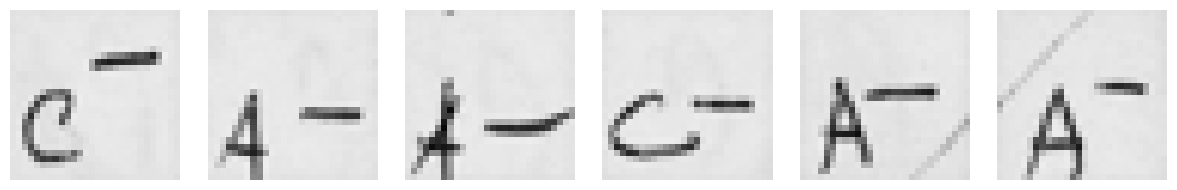

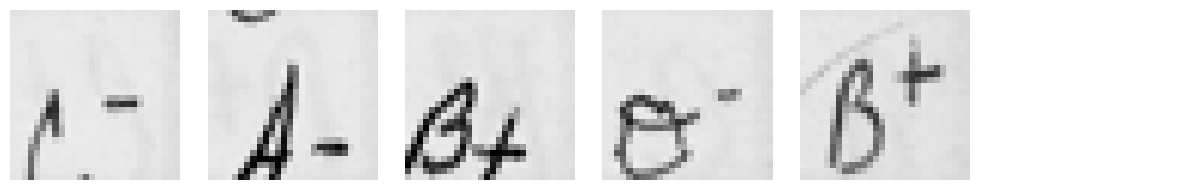

In [3]:
from gradesheet_fxns import *
directory = "./cropped_images/images1971"

# Get only files (ignores subdirectories)
filenames = [f for f in os.listdir(directory) if os.path.isfile(os.path.join(directory, f))]
print(filenames)
for fname in filenames:
    src =os.path.join(directory,fname)
    img, bw, xs, ys, cells, cells_gray= get_letters(src)
    # original cells is used to calculate darkness, but cells_gray is used to plot the cells and save
    darknesses = get_darknesses(cells, xs, ys)
    # for darkness in darknesses:
    #     if darkness[1] == 10:  # only print darkness for column 10
    #         print(f"Cell darkness: {darknesses[darkness]:.4f}")
    #TODO: filter cells
    cells_gray = resize_cells(cells_gray, ys, crop_margin = 4)

    # Takes darkness values and tests if they have a darkness value of more than 0.005
    # If they do, add that cell into a new dictionary with all other cells above that level of darkness

    filtered_cells = {}
    keys_ls = []
    for key in darknesses:
        if darknesses[key] > 0.005:
            keys_ls.append(key)
            filtered_cells[key] = cells_gray[key]

    # Plots some cells in filtered_cells, unless that cell doesn't exist because it was removed in the previous stage
    # This is for visual confirmation as far as I can tell. We don't save these values anywhere else.
    for i in range(7,10):
        plot_cell_dict(filtered_cells,ys, selected_column=i)

    # Motify save cells to only take key list of new filtered_cells
    
    save_cells(filtered_cells, keys_ls, src_filename = fname, out_dir = "./square_images") 
 

create the output directory square_images to store the images in; then the save command should work. 

In [ ]:
save_cells(filtered_cells, ys, src_filename = fname, out_dir = "./square_images") 

In [ ]:
# what grid positions did it find
print(xs)
print(ys)

[330, 468, 592, 719, 847, 982, 1107, 1232, 1363, 1501, 1639, 1777]
[115, 123, 222, 322, 421, 520, 619, 718, 774, 817, 916, 1015]


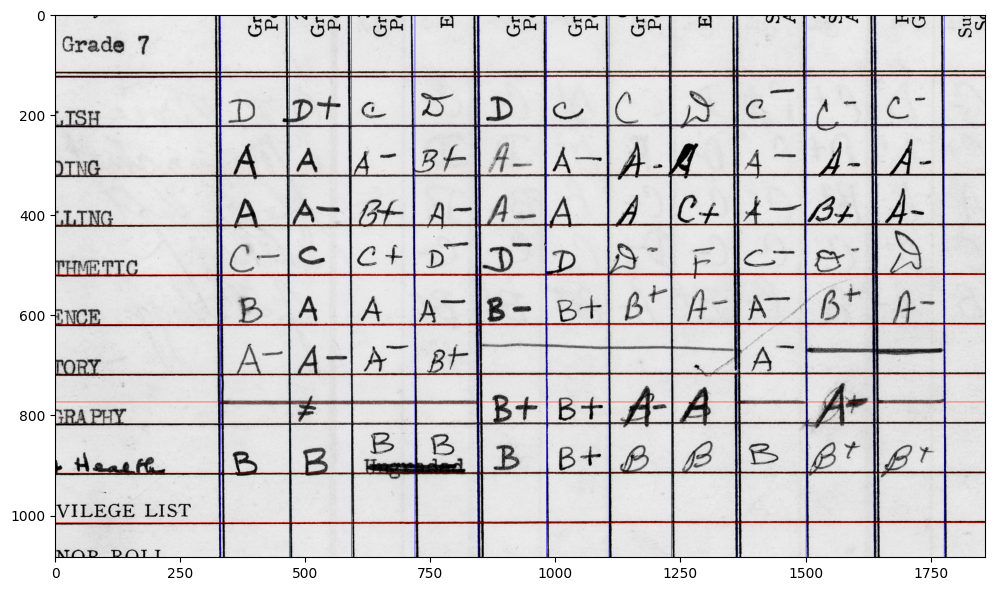

12 vertical lines, 12 horizontal lines


In [ ]:

# Check the overlay to make sure the grid is correctly detected. convert to color so the lines show up in red/blue
overlay = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

H, W = img.shape

for y in ys:
    cv2.line(overlay, (0, y), (W - 1, y), (0, 0, 255), 1)   # horizontal = red
for x in xs:
    cv2.line(overlay, (x, 0), (x, H - 1), (255, 0, 0), 1)   # vertical = blue

plt.figure(figsize=(12, 16))
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.show()
print(f"{len(xs)} vertical lines, {len(ys)} horizontal lines")
